## 1. Import libraries

In [59]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import tiktoken
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from torch.utils.data import TensorDataset, DataLoader

## 2. Load the dataset

In [60]:
df = pd.read_csv("IMDB Dataset.csv")

print(df.head())
print("Dataset shape:", df.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
Dataset shape: (50000, 2)


## 3. Check the dataset

In [61]:
print(df.info())
print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Missing values:
review       0
sentiment    0
dtype: int64


## 4. Convert sentiment into numerical labels

In [62]:
df["label"] = df["sentiment"].map({
    "positive": 1,
    "negative": 0
})

texts = df["review"].astype(str).values
labels = df["label"].values

print("Total reviews:", len(texts))

Total reviews: 50000


## 5. Split the dataset

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    texts,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 40000
Testing reviews: 10000


## 6. Initialize the tokenizer

In [64]:
tokenizer = tiktoken.get_encoding("cl100k_base")

VOCAB_SIZE = tokenizer.n_vocab + 1

print("Vocabulary size:", VOCAB_SIZE)

Vocabulary size: 100278


## 7. Convert text into tokens

In [65]:
def encode_review(review):
    token_ids = tokenizer.encode(review)
    return [token + 1 for token in token_ids]

## 8. Set maximum review length

In [66]:
MAX_LENGTH = 200

## 9. Apply padding and truncation

In [67]:
def prepare_review(review):
    tokens = encode_review(review)

    if len(tokens) > MAX_LENGTH:
        tokens = tokens[:MAX_LENGTH]

    else:
        tokens = tokens + [0] * (MAX_LENGTH - len(tokens))

    return tokens

## 10. Prepare a smaller dataset

In [68]:
X_train_small = X_train[:3000]
y_train_small = y_train[:3000]

X_test_small = X_test[:1000]
y_test_small = y_test[:1000]

## 11. Tokenize all reviews

In [69]:
X_train_encoded = [
    prepare_review(review) for review in X_train_small
]

X_test_encoded = [
    prepare_review(review) for review in X_test_small
]

print("Training data prepared:", len(X_train_encoded))
print("Testing data prepared:", len(X_test_encoded))

Training data prepared: 3000
Testing data prepared: 1000


## 12. Convert into PyTorch tensors

In [70]:
X_train_tensor = torch.tensor(
    X_train_encoded, dtype=torch.long
)

X_test_tensor = torch.tensor(
    X_test_encoded, dtype=torch.long
)

y_train_tensor = torch.tensor(
    y_train_small, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_small, dtype=torch.float32
)

print("Training tensor:", X_train_tensor.shape)
print("Testing tensor:", X_test_tensor.shape)

Training tensor: torch.Size([3000, 200])
Testing tensor: torch.Size([1000, 200])


## 13. Create DataLoaders

In [71]:
BATCH_SIZE = 32

train_dataset = TensorDataset(
    X_train_tensor, y_train_tensor
)

test_dataset = TensorDataset(
    X_test_tensor, y_test_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 94
Testing batches: 32


## 14. Define the Simple RNN model

In [72]:
class MovieSentimentRNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.embedding = nn.Embedding(
            VOCAB_SIZE, 128, padding_idx=0
        )

        self.rnn = nn.RNN(
            input_size=128,
            hidden_size=128,
            batch_first=True
        )

        self.fc = nn.Linear(128, 1)

    def forward(self, x):

        x = self.embedding(x)

        _, hidden = self.rnn(x)

        output = self.fc(hidden[-1])

        return output.squeeze(1)

## 15. Initialize the model

In [73]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = MovieSentimentRNN().to(device)

print("Device:", device)
print(model)

Device: cpu
MovieSentimentRNN(
  (embedding): Embedding(100278, 128, padding_idx=0)
  (rnn): RNN(128, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


## 16. Define loss and optimizer

In [74]:
loss_function = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0005
)

## 17. Train the model

In [76]:
EPOCHS = 5
train_losses = []

for epoch in range(EPOCHS):

    model.train()
    running_loss = 0

    for reviews, labels in train_loader:

        reviews = reviews.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        predictions = model(reviews)

        loss = loss_function(predictions, labels)

        loss.backward()

        nn.utils.clip_grad_norm_(
            model.parameters(), max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} - "
        f"Loss: {epoch_loss:.4f}"
    )

Epoch 1/5 - Loss: 0.6973
Epoch 2/5 - Loss: 0.6720
Epoch 3/5 - Loss: 0.6470
Epoch 4/5 - Loss: 0.6169
Epoch 5/5 - Loss: 0.5732


## 18. Plot training loss

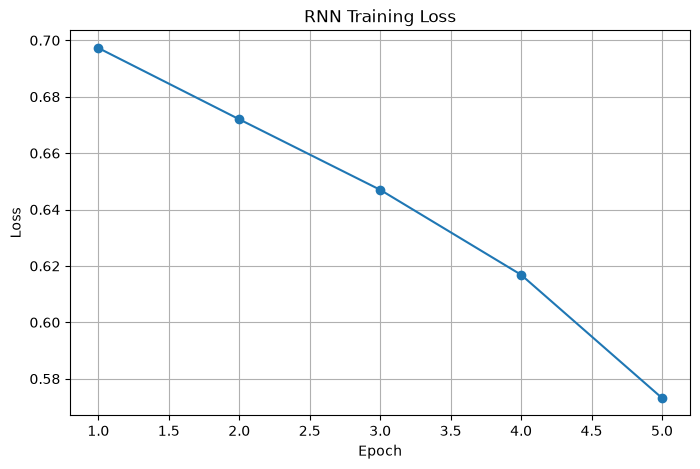

In [77]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o"
)

plt.title("RNN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

## 19. Evaluate the model

In [78]:
model.eval()

predictions_list = []
actual_list = []

with torch.no_grad():

    for reviews, labels in test_loader:

        reviews = reviews.to(device)

        outputs = model(reviews)

        predicted = (
            torch.sigmoid(outputs) >= 0.5
        ).int()

        predictions_list.extend(
            predicted.cpu().numpy()
        )

        actual_list.extend(
            labels.numpy().astype(int)
        )

## 20. Calculate performance metrics

In [79]:
accuracy = accuracy_score(actual_list, predictions_list)

precision = precision_score(
    actual_list, predictions_list, zero_division=0
)

recall = recall_score(
    actual_list, predictions_list, zero_division=0
)

f1 = f1_score(
    actual_list, predictions_list, zero_division=0
)

print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))

Accuracy: 0.501
Precision: 0.507
Recall: 0.7112
F1 Score: 0.592


## 21. Classification report

In [80]:
print(
    classification_report(
        actual_list,
        predictions_list,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Negative       0.49      0.28      0.36       491
    Positive       0.51      0.71      0.59       509

    accuracy                           0.50      1000
   macro avg       0.50      0.50      0.47      1000
weighted avg       0.50      0.50      0.48      1000



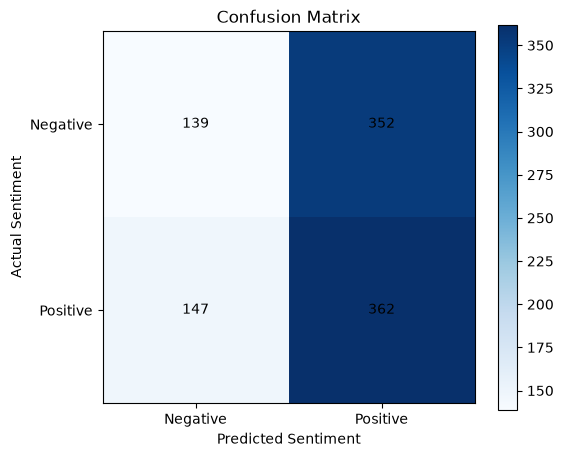

In [81]:
cm = confusion_matrix(
    actual_list,
    predictions_list,
    labels=[0, 1]
)

plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

for row in range(2):
    for col in range(2):
        plt.text(
            col, row,
            cm[row, col],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

In [82]:
def predict_sentiment(review):

    model.eval()

    encoded = prepare_review(review)

    input_data = torch.tensor(
        [encoded], dtype=torch.long
    ).to(device)

    with torch.no_grad():

        output = model(input_data)

        probability = torch.sigmoid(output).item()

    if probability >= 0.5:
        result = "Positive"
    else:
        result = "Negative"

    print("Review:", review)
    print("Positive probability:", round(probability, 4))
    print("Predicted sentiment:", result)

In [83]:
predict_sentiment(
    "The movie was wonderful and the acting was excellent."
)

Review: The movie was wonderful and the acting was excellent.
Positive probability: 0.5535
Predicted sentiment: Positive


In [84]:
predict_sentiment(
    "The movie was boring and the story was disappointing."
)

Review: The movie was boring and the story was disappointing.
Positive probability: 0.5535
Predicted sentiment: Positive


In [85]:
my_review = "I enjoyed watching this movie. It was entertaining."

predict_sentiment(my_review)

Review: I enjoyed watching this movie. It was entertaining.
Positive probability: 0.5535
Predicted sentiment: Positive
